# Scientific Interest in AMR

This notebook is the yearly version of the scientific-interest workflow. It uses the refined second-pass output `pmids_results_positive_yearly_refined.parquet`, so each observation is a true `(pathogen, antibiotic, year)` count after refined LLM screening.

The main idea stays the same:

- `count` is the observed AMR-positive publication count for one `(pathogen, antibiotic, year)` row
- `bg_pathogen_n` is the total publication background for that pathogen in the same year
- `bg_antibiotic_n` is the total publication background for that antibiotic in the same year
- the pooled model defines the expected AMR count from general pathogen and antibiotic attention
- `SI` is the residual gap between the observed base-10 log-count and that pooled expectation

Because the data are now yearly, the notebook can work directly on annual points without fitting over 5-year interval end-years.


In [2]:
%config InlineBackend.figure_format = 'retina'
import sys
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.linear_model import Ridge
from IPython.display import display

PROJECT_ROOT = None
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "amr").exists():
        PROJECT_ROOT = candidate
        break
    nested_candidate = candidate / "Antimicrobial Resistance"
    if (nested_candidate / "amr").exists():
        PROJECT_ROOT = nested_candidate
        break

if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate the project root containing the 'amr' package.")

ARCHIVE_ROOT = PROJECT_ROOT / "archive"
if str(ARCHIVE_ROOT) not in sys.path:
    sys.path.insert(0, str(ARCHIVE_ROOT))

from amr_legacy.scientific_interest import (
    plot_yearly_si_pair,
    display_si_amr_pareto_front,
    plot_yearly_si_prediction_for_pareto_pairs,
)

ARCHIVE_DIR = PROJECT_ROOT / "archive"
LEGACY_ASSETS_DIR = ARCHIVE_DIR / "legacy_assets"


In [3]:
ANTIBIOTIC_METADATA_PATH = LEGACY_ASSETS_DIR / "antibiotic_list.xlsx"

antibiotics_df = pd.read_excel(ANTIBIOTIC_METADATA_PATH)
for col in antibiotics_df.columns:
    col_list = antibiotics_df[col].values
    print(f'#{col}: {len(set(col_list))}')
N_ROWS = 10
display(antibiotics_df.sample(min(N_ROWS, len(antibiotics_df)), random_state=None))

#Antibiotic: 245
#Class: 39
#Simplified categories: 15
#High level categories: 11
#Origin: 2


,Antibiotic,Class,Simplified categories,High level categories,Origin
49,Cefoselis,Fourth-generation-cephalosporins,Cephalosporins,Beta lactam and related,Naturally occurring/modified
39,Cefetamet-pivoxil,Third-generation-cephalosporins,Cephalosporins,Beta lactam and related,Naturally occurring/modified
53,Cefoxitin,Second-generation-cephalosporins,Cephalosporins,Beta lactam and related,Naturally occurring/modified
42,Cefmenoxime,Third-generation-cephalosporins,Cephalosporins,Beta lactam and related,Naturally occurring/modified
91,Azidocillin,Penicillins,Penicillins,Beta lactam and related,Naturally occurring/modified
17,Amoxicillin/clavulanic-acid,Beta-lactam/beta-lactamase-inhibitor,Beta-lactamase-inhibitors/combinations,Beta lactam and related,Naturally occurring/modified
29,Cefamandole,Second-generation-cephalosporins,Cephalosporins,Beta lactam and related,Naturally occurring/modified
104,Mecillinam,Penicillins,Penicillins,Beta lactam and related,Naturally occurring/modified
163,Tedizolid,Oxazolidinones,Miscellaneous,Other,Synthetic
15,Streptomycin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified


## Load yearly AMR counts and yearly backgrounds

This notebook expects the refined yearly positive-AMR parquet created in `6_1_refined_yearly_amr_filter.ipynb` (`pmids_results_positive_yearly_refined.parquet`). The pathogen and antibiotic background tables were already collected at yearly resolution, so we can merge them directly on `year`.


In [4]:
REFINED_SCREEN_PATH = LEGACY_ASSETS_DIR / "pmids_results_positive_yearly_refined_screen.parquet"
REFINED_PAIR_PMID_PATH = LEGACY_ASSETS_DIR / "pmids_results_positive_yearly_refined_pair_pmid.parquet"
YEARLY_PATH = LEGACY_ASSETS_DIR / "pmids_results_positive_yearly_refined.parquet"
PATHOGEN_BG_PATH = PROJECT_ROOT / "pathogen_tiab_counts.parquet"
ANTIBIOTIC_BG_PATH = PROJECT_ROOT / "antibiotic_tiab_counts.parquet"

yearly_df = pd.read_parquet(YEARLY_PATH)
pathogen_bg_df = pd.read_parquet(PATHOGEN_BG_PATH).rename(columns={"count": "bg_pathogen_n"})
antibiotic_bg_df = pd.read_parquet(ANTIBIOTIC_BG_PATH).rename(columns={"count": "bg_antibiotic_n"})

amr_yearly_df = (
    yearly_df.merge(pathogen_bg_df, on=["pathogen", "year"], how="left")
    .merge(antibiotic_bg_df, on=["antibiotic", "year"], how="left")
    .copy()
)

amr_yearly_df["count"] = pd.to_numeric(amr_yearly_df["count"], errors="coerce")
amr_yearly_df["bg_pathogen_n"] = pd.to_numeric(amr_yearly_df["bg_pathogen_n"], errors="coerce")
amr_yearly_df["bg_antibiotic_n"] = pd.to_numeric(amr_yearly_df["bg_antibiotic_n"], errors="coerce")
amr_yearly_df["log_count"] = np.log10(1 + amr_yearly_df["count"])
amr_yearly_df["log_bg_pathogen_n"] = np.log10(1 + amr_yearly_df["bg_pathogen_n"])
amr_yearly_df["log_bg_antibiotic_n"] = np.log10(1 + amr_yearly_df["bg_antibiotic_n"])

amr_yearly_df = amr_yearly_df.dropna(
    subset=["count", "bg_pathogen_n", "bg_antibiotic_n", "log_count", "log_bg_pathogen_n", "log_bg_antibiotic_n"]
).reset_index(drop=True)

print(f"yearly AMR rows: {len(amr_yearly_df):,}")
print(f"unique pathogen-antibiotic pairs: {amr_yearly_df[['pathogen', 'antibiotic']].drop_duplicates().shape[0]:,}")
print(f"year span: {int(amr_yearly_df['year'].min())} to {int(amr_yearly_df['year'].max())}")

yearly AMR rows: 41,278
unique pathogen-antibiotic pairs: 9,330
year span: 1975 to 2025


In [5]:
N_ROWS = 10
display(amr_yearly_df.sample(min(N_ROWS, len(amr_yearly_df)), random_state=None))

,pathogen,antibiotic,year,pmids,count,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n
15174,Haemophilus influenzae,Chloramphenicol,1983,"[6341948, 6424404, 6559193, 6580737, 6644441]",5,303.0,417.0,0.778151,2.482874,2.621176
9734,Enterococcus casseliflavus,Levofloxacin,2006,[16971033],1,15.0,346.0,0.301030,1.204120,2.540329
28488,Salmonella enterica,Streptomycin,1981,"[6973847, 7041408]",2,442.0,211.0,0.477121,2.646404,2.326336
25190,Providencia stuartii,Ciprofloxacin,1995,[8522464],1,8.0,513.0,0.301030,0.954243,2.710963
21809,Mycobacterium tuberculosis,Streptomycin,1975,"[59442, 59443, 816363]",3,143.0,253.0,0.602060,2.158362,2.404834
12810,Escherichia coli,Chloramphenicol,2018,"[28604274, 28810248, 29111433, 29279444, 29307...",20,9914.0,541.0,1.322219,3.996293,2.733999
862,Acinetobacter baumannii,Piperacillin,2020,"[31832843, 31833386, 32000693, 32692197, 32748...",6,1120.0,505.0,0.845098,3.049606,2.704151
37647,Streptococcus pneumoniae,Cefaclor,1992,[1452492],1,365.0,88.0,0.301030,2.563481,1.949390
7472,Corynebacterium diphtheriae,Cefotaxime,2016,[27585941],1,34.0,285.0,0.301030,1.544068,2.456366
12393,Escherichia coli,Cefazolin,2001,"[11545486, 12733347]",2,6356.0,63.0,0.477121,3.803252,1.806180


## Pooled yearly baseline model

We fit the same pooled baseline as before, but now at yearly resolution:

`log10(1 + count)` = `alpha` + `u_pathogen` + `v_antibiotic` + `beta_path * log10(1 + bg_pathogen_n)` + `beta_ab * log10(1 + bg_antibiotic_n)`

Here:

- `alpha` is the global intercept
- `u_pathogen` is the pathogen-specific pooled effect
- `v_antibiotic` is the antibiotic-specific pooled effect
- `beta_path` and `beta_ab` tell us how expected AMR counts scale with yearly pathogen and antibiotic attention

Once the model is fitted, the yearly scientific-interest score is:

`SI = log10(1 + count) - expected_log_count_global`


In [6]:
alpha = 1.0

pathogen_dummies = pd.get_dummies(amr_yearly_df["pathogen"].astype(str), prefix="pathogen", dtype=float)
antibiotic_dummies = pd.get_dummies(amr_yearly_df["antibiotic"].astype(str), prefix="antibiotic", dtype=float)

design_df = pd.concat(
    [
        amr_yearly_df[["log_bg_pathogen_n", "log_bg_antibiotic_n"]].reset_index(drop=True),
        pathogen_dummies.reset_index(drop=True),
        antibiotic_dummies.reset_index(drop=True),
    ],
    axis=1,
)

response = amr_yearly_df["log_count"].to_numpy(dtype=float)
pooled_model = Ridge(alpha=alpha, fit_intercept=True)
pooled_model.fit(design_df, response)

si_df = amr_yearly_df.copy()
si_df["expected_log_count_global"] = pooled_model.predict(design_df)
si_df["expected_count_global"] = np.clip(np.power(10.0, si_df["expected_log_count_global"]) - 1.0, 0.0, None)
si_df["SI"] = si_df["log_count"] - si_df["expected_log_count_global"]

display(
    si_df[
        [
            "pathogen",
            "antibiotic",
            "year",
            "count",
            "bg_pathogen_n",
            "bg_antibiotic_n",
            "expected_count_global",
            "SI",
        ]
    ].head()
)


,pathogen,antibiotic,year,count,bg_pathogen_n,bg_antibiotic_n,expected_count_global,SI
0,Abiotrophia defectiva,Cefepime,2016,1,17.0,200.0,0.996784,0.000699
1,Abiotrophia defectiva,Cefotaxime,2016,1,17.0,285.0,1.215138,-0.044371
2,Abiotrophia defectiva,Ceftriaxone,2013,1,4.0,509.0,0.791553,0.047800
3,Abiotrophia defectiva,Ciprofloxacin,2013,1,4.0,1209.0,1.307610,-0.062132
4,Abiotrophia defectiva,Clindamycin,2000,1,7.0,184.0,0.875313,0.027956


## Inspect the fitted baseline

The two continuous coefficients are usually the most interpretable summary of the pooled model, because they show how expected AMR publication volume scales with general yearly attention to the pathogen and the antibiotic.


In [7]:
coef_df = pd.DataFrame({"feature": design_df.columns, "coefficient": pooled_model.coef_})
display(coef_df[coef_df["feature"].isin(["log_bg_pathogen_n", "log_bg_antibiotic_n"])])
print("Model intercept:", float(pooled_model.intercept_))


,feature,coefficient
0,log_bg_pathogen_n,0.163529
1,log_bg_antibiotic_n,0.146369


Model intercept: -0.29126719385277905


## Rank pairs by average yearly scientific interest

This gives a compact overview of which pathogen-antibiotic pairs are persistently above the pooled yearly baseline.


In [8]:
pair_summary_df = (
    si_df.groupby(["pathogen", "antibiotic"], as_index=False)
    .agg(
        mean_SI=("SI", "mean"),
        total_count=("count", "sum"),
        mean_count=("count", "mean"),
        n_years=("year", "nunique"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .sort_values(["mean_SI", "total_count"], ascending=[False, False])
    .reset_index(drop=True)
)

display(pair_summary_df.head(20))


,pathogen,antibiotic,mean_SI,total_count,mean_count,n_years,first_year,last_year
0,Enterococcus faecium,Vancomycin,0.913343,2019,54.567568,37,1988,2024
1,Helicobacter pylori,Clarithromycin,0.825114,1714,53.562500,32,1993,2024
2,Helicobacter pylori,Metronidazole,0.672010,1271,35.305556,36,1985,2024
3,Mycobacterium tuberculosis,Rifampicin,0.671281,2105,46.777778,45,1975,2025
4,Haemophilus influenzae,Ampicillin,0.654727,967,19.340000,50,1975,2024
5,Escherichia coli,Ampicillin,0.647039,2966,59.320000,50,1975,2024
6,Lactococcus lactis,Sulfathiazole,0.624988,1,1.000000,1,1985,1985
7,Enterococcus faecalis,Vancomycin,0.598217,809,21.864865,37,1988,2024
8,Staphylococcus aureus,Oxacillin,0.569685,1522,31.061224,49,1975,2024
9,Acinetobacter baumannii,Colistin,0.554375,555,27.750000,20,2005,2024


## Plot one yearly pair trajectory

With yearly data, we can plot the observed count trajectory and the yearly `SI` directly. The optional rolling mean just makes the annual pattern easier to read; it is not part of the SI definition.


Random eligible pair: Klebsiella pneumoniae vs Ceftazidime (n_train_years=36, total_count=630)


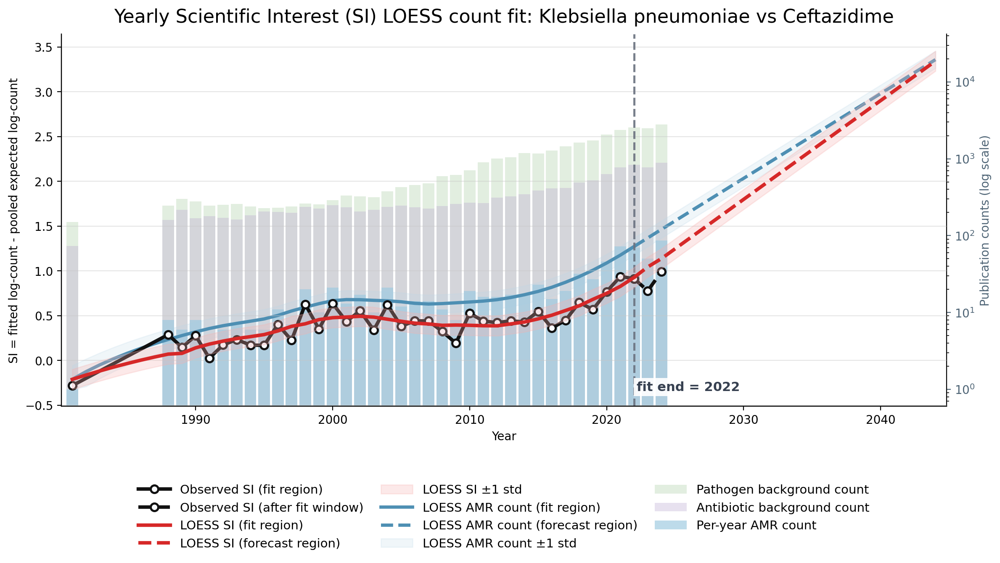

Observed vs predicted yearly AMR counts


,year,observed_count,predicted_count,diff,pct_error
0,1981,1,1,0,0.000000
1,1988,8,4,4,50.000000
2,1989,6,5,1,16.666667
3,1990,8,6,2,25.000000
4,1991,4,6,-2,-50.000000
5,1992,6,7,-1,-16.666667
6,1993,7,7,0,0.000000
7,1994,6,8,-2,-33.333333
8,1995,6,8,-2,-33.333333
9,1996,11,9,2,18.181818


LOESS fraction: 0.6
LOESS degree: 2
Training residual std on log-count scale: 0.11120732928486032
Latest observed year: 2024


In [9]:
MIN_TRAIN_YEARS = 10
MIN_TOTAL_AMR_COUNT = 200

eligible_pairs = (
    si_df.loc[si_df["year"].between(1970, 2022)]
    .groupby(["pathogen", "antibiotic"], as_index=False)
    .agg(
        n_train_years=("year", "nunique"),
        total_count=("count", "sum"),
    )
    .query("n_train_years >= @MIN_TRAIN_YEARS and total_count >= @MIN_TOTAL_AMR_COUNT")
    .reset_index(drop=True)
)

if eligible_pairs.empty:
    raise ValueError(
        f"No pathogen-group pairs have at least {MIN_TRAIN_YEARS} training years "
        f"and total AMR count >= {MIN_TOTAL_AMR_COUNT}."
    )

example_row = eligible_pairs.sample(1, random_state=None).iloc[0]
example_pathogen = example_row["pathogen"]
example_group = example_row["antibiotic"]

print(
    f"Random eligible pair: {example_pathogen} vs {example_group} "
    f"(n_train_years={example_row['n_train_years']}, total_count={example_row['total_count']})"
)

result = plot_yearly_si_pair(
    si_df=si_df,
    pathogen=example_pathogen,
    antibiotic=example_group,
    fit_start_year=1970,
    fit_end_year=2022,
    num_additional_years=20,
    loess_frac=0.6,
    loess_degree=2,
    tail_damping_years=None,
)

print("Observed vs predicted yearly AMR counts")
display(result["comparison_df"])
# display(result["detailed_comparison_df"])
print("LOESS fraction:", result["loess_fit"]["frac"])
print("LOESS degree:", result["loess_fit"]["degree"])
print("Training residual std on log-count scale:", result["loess_fit"]["residual_std"])
print("Latest observed year:", result["latest_available_year"])


## Pareto-front examples

This is the yearly equivalent of the interval Pareto workflow: first identify pairs that are non-dominated in mean `SI` and mean AMR count, then generate yearly prediction plots for those pairs.


,pareto_shell,pathogen,antibiotic,mean_SI,mean_count,total_count,n_intervals,n_years,latest_year
0,1,Enterococcus faecium,Vancomycin,0.913343,54.567568,2019,37,37,2024
1,1,Escherichia coli,Ampicillin,0.647039,59.320000,2966,50,50,2024
2,1,Escherichia coli,Colistin,0.303562,61.105263,1161,19,19,2024
3,2,Helicobacter pylori,Clarithromycin,0.825114,53.562500,1714,32,32,2024
4,2,Escherichia coli,Ciprofloxacin,0.528421,56.945946,2107,37,37,2024
5,3,Helicobacter pylori,Metronidazole,0.672010,35.305556,1271,36,36,2024
6,3,Mycobacterium tuberculosis,Rifampicin,0.671281,46.777778,2105,45,45,2025
7,4,Haemophilus influenzae,Ampicillin,0.654727,19.340000,967,50,50,2024
8,4,Enterococcus faecalis,Vancomycin,0.598217,21.864865,809,37,37,2024
9,4,Staphylococcus aureus,Oxacillin,0.569685,31.061224,1522,49,49,2024


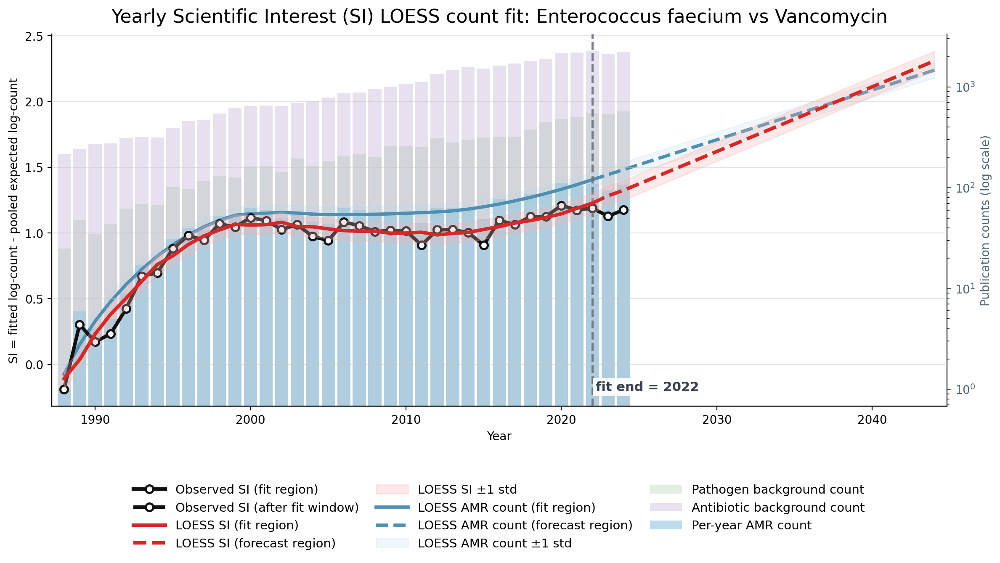

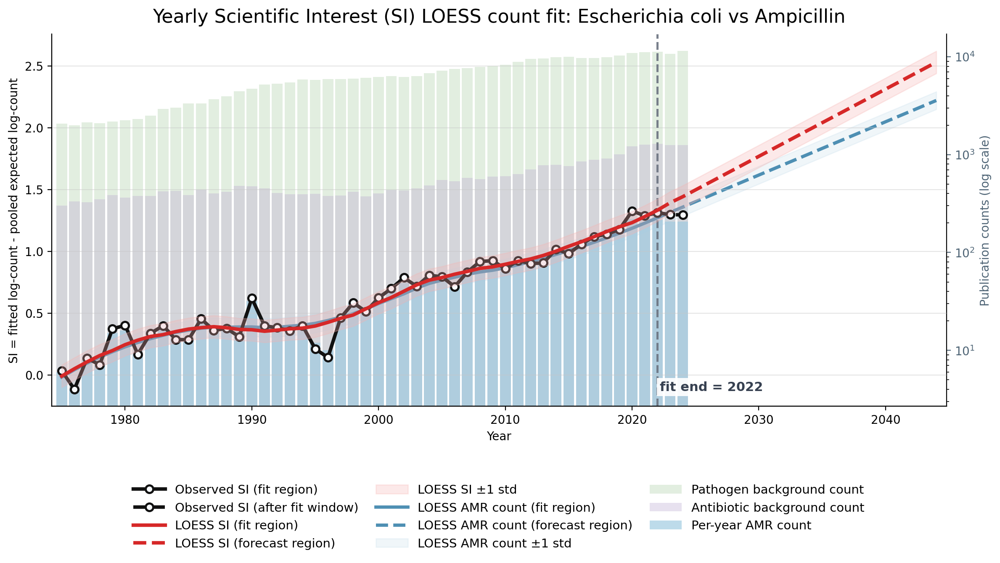

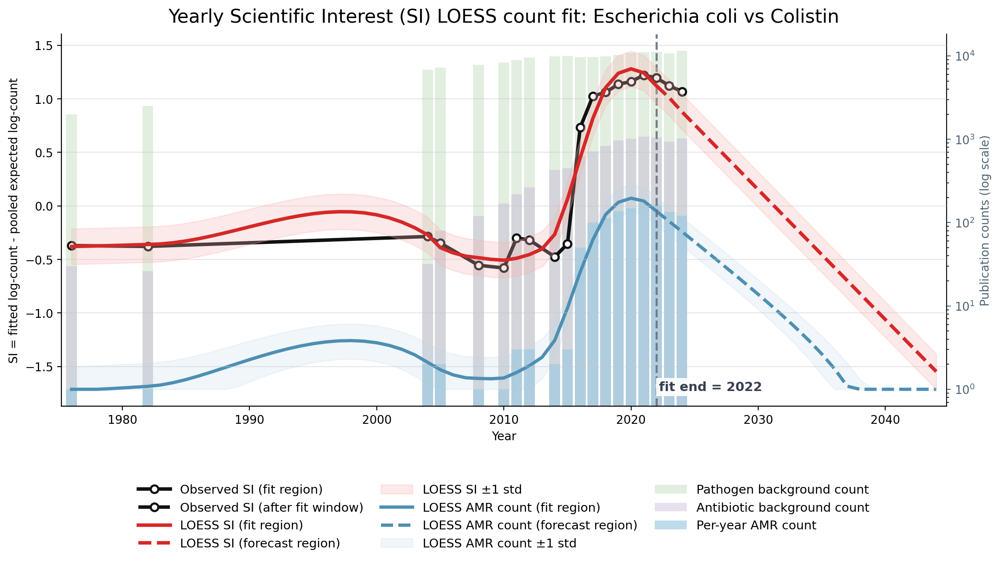

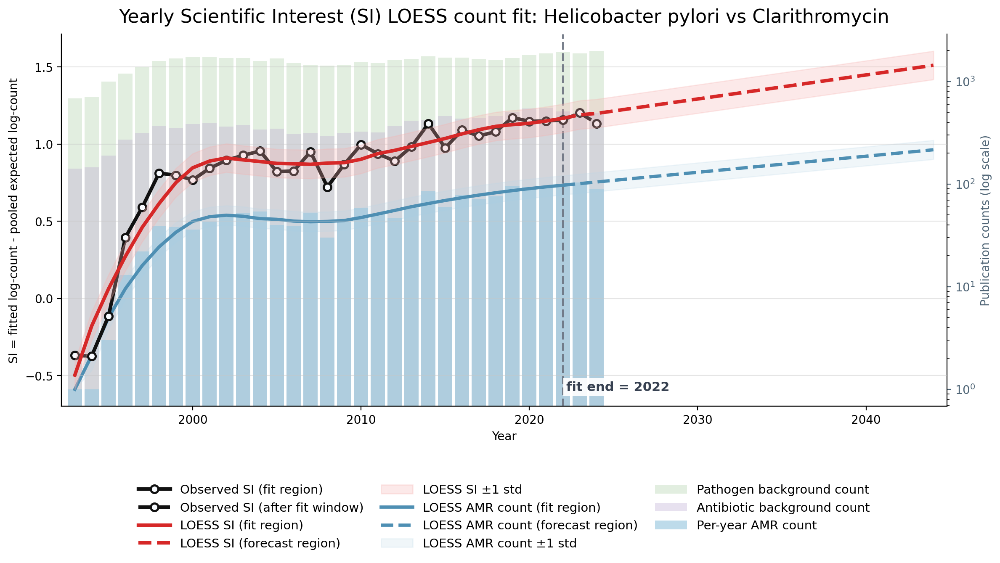

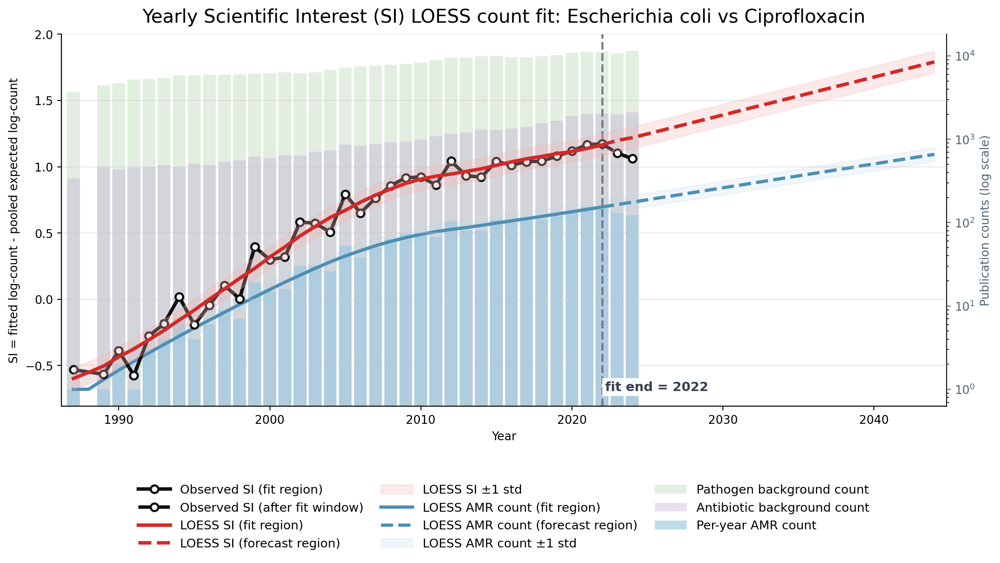

...

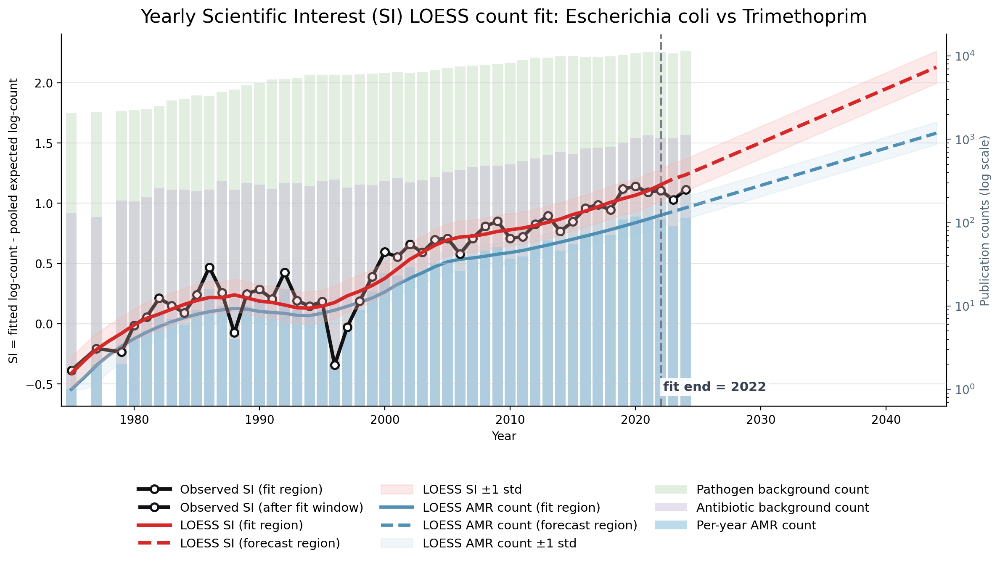

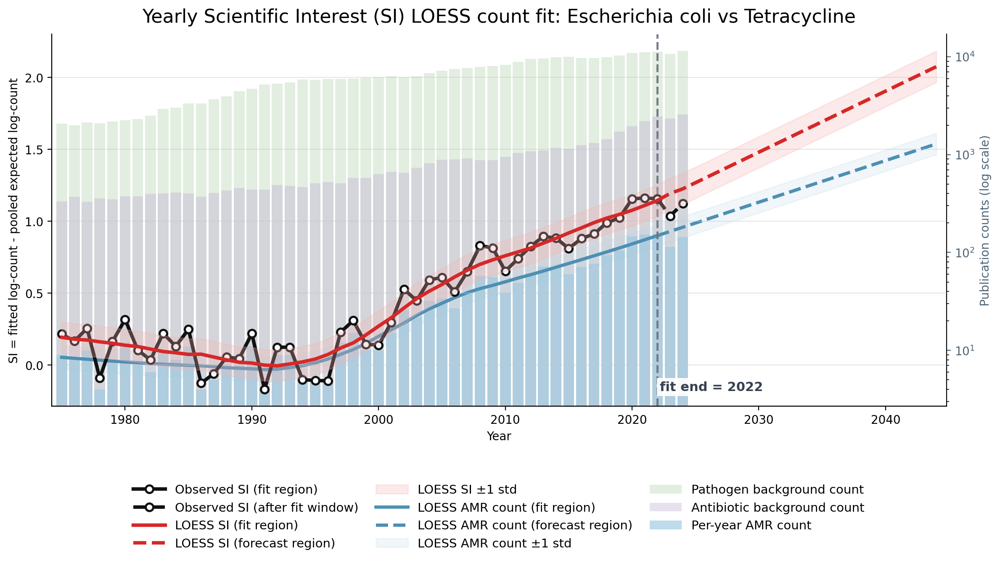

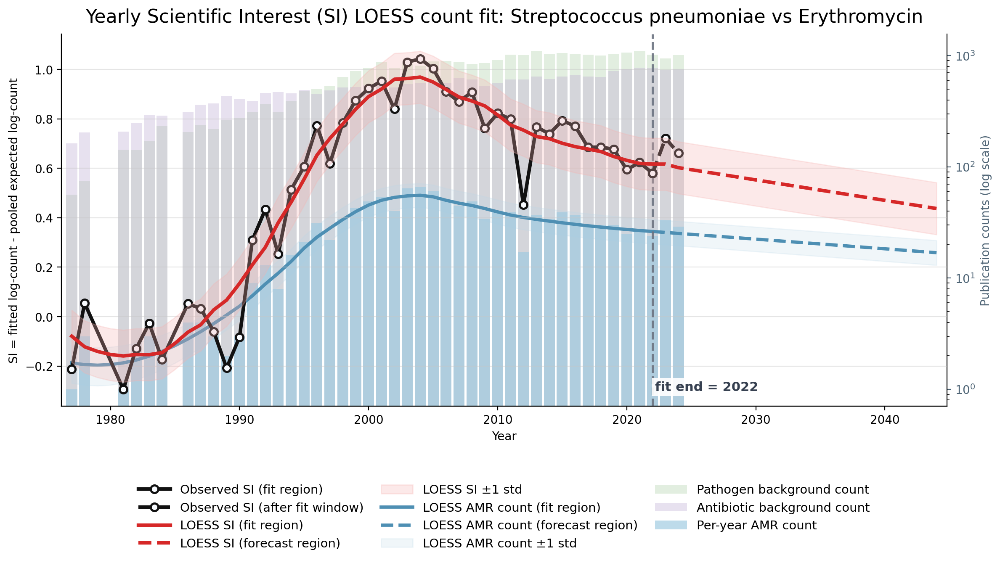

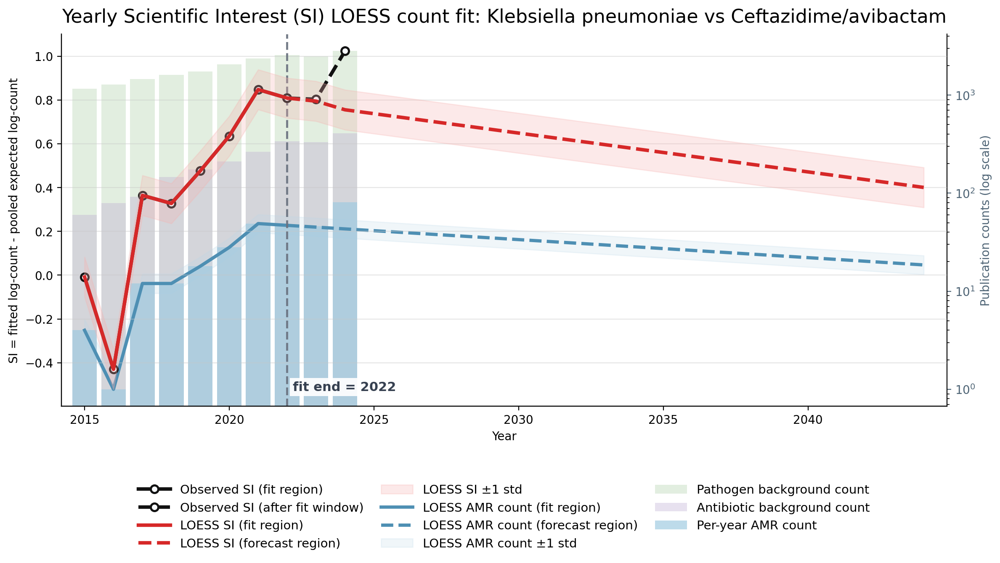

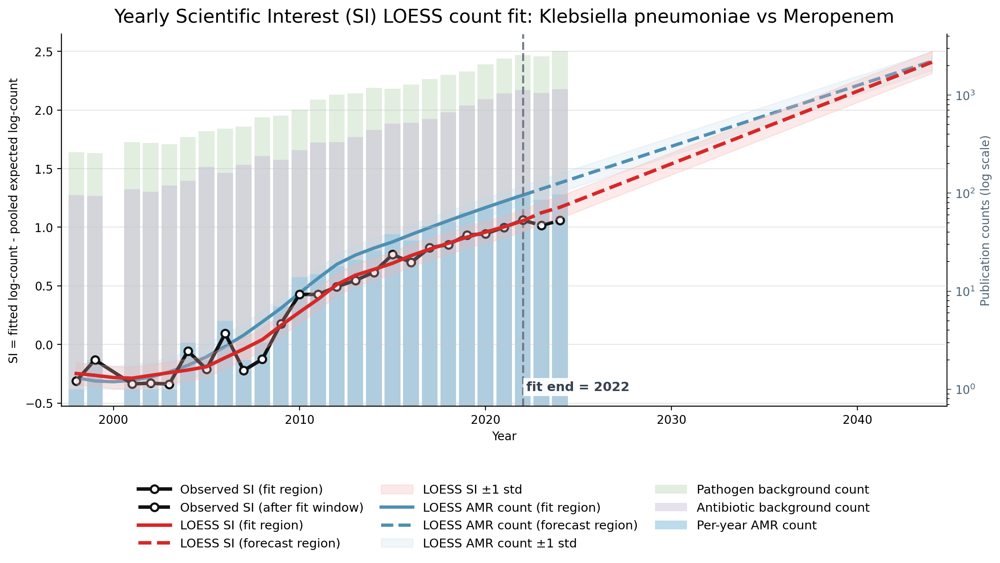

In [10]:
# Example:
n_pareto_shells = 6
pareto_df = display_si_amr_pareto_front(si_df, n_pareto_shells=n_pareto_shells)
pareto_plot_results = plot_yearly_si_prediction_for_pareto_pairs(
    si_df,
    pareto_df,
    fit_start_year=1970,
    fit_end_year=2022,
    num_additional_years=20,
    loess_frac=0.6,
    loess_degree=2,
    tail_damping_years=None,
    n_pareto_shells=n_pareto_shells,
    save_dir="pareto_pngs_yearly",
)


In [11]:
%%time
from amr.scientific_interest import rank_yearly_pairs_by_future_si_shift

rank_df = rank_yearly_pairs_by_future_si_shift(
    si_df,
    fit_start_year=1970,
    fit_end_year=2022,
    num_future_years=20,
    verbose=True,
)


[1/9330] ranking Abiotrophia defectiva vs Cefepime (9329 remaining)
[1/9330] skipping Abiotrophia defectiva vs Cefepime: Need at least 3 observed years between 1970 and 2022; found 1.
[2/9330] ranking Abiotrophia defectiva vs Cefotaxime (9328 remaining)
[2/9330] skipping Abiotrophia defectiva vs Cefotaxime: Need at least 3 observed years between 1970 and 2022; found 1.
[3/9330] ranking Abiotrophia defectiva vs Ceftriaxone (9327 remaining)
[3/9330] skipping Abiotrophia defectiva vs Ceftriaxone: Need at least 3 observed years between 1970 and 2022; found 1.
[4/9330] ranking Abiotrophia defectiva vs Ciprofloxacin (9326 remaining)
[4/9330] skipping Abiotrophia defectiva vs Ciprofloxacin: Need at least 3 observed years between 1970 and 2022; found 1.
[5/9330] ranking Abiotrophia defectiva vs Clindamycin (9325 remaining)
[5/9330] skipping Abiotrophia defectiva vs Clindamycin: Need at least 3 observed years between 1970 and 2022; found 2.
[6/9330] ranking Abiotrophia defectiva vs Daptomycin (

In [12]:
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

from amr.scientific_interest import select_interesting_yearly_rank_cases

RANK_PATH = LEGACY_ASSETS_DIR / "si_yearly_rank_shift_fit_1970_2022_ref_2022_future_2042.parquet"

rank_df = pd.read_parquet(RANK_PATH)

interesting_df = select_interesting_yearly_rank_cases(
    rank_df,
    min_current_predicted_count=10,
    min_si_change=0.4,
    min_post_fit_observed_years=1,
    max_post_fit_si_abs_pct_error_mean=40,
    fallback_top_n=0,
)
minimal_df = interesting_df[
    [
        "pathogen",
        "antibiotic",
        "interest_score",
        "si_change",
        "current_predicted_count",
        "future_predicted_count",
        "post_fit_si_abs_pct_error_mean",
    ]
].copy()
minimal_df


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,post_fit_si_abs_pct_error_mean
0,Klebsiella pneumoniae,Ceftazidime,0.729044,0.438408,72.162189,204.608569,21.398033
1,Streptococcus pyogenes,Doxycycline,0.009589,1.757707,38.692617,2271.046546,NaN
2,Acinetobacter calcoaceticus,Tetracycline,0.003565,1.002655,14.301218,152.950406,NaN


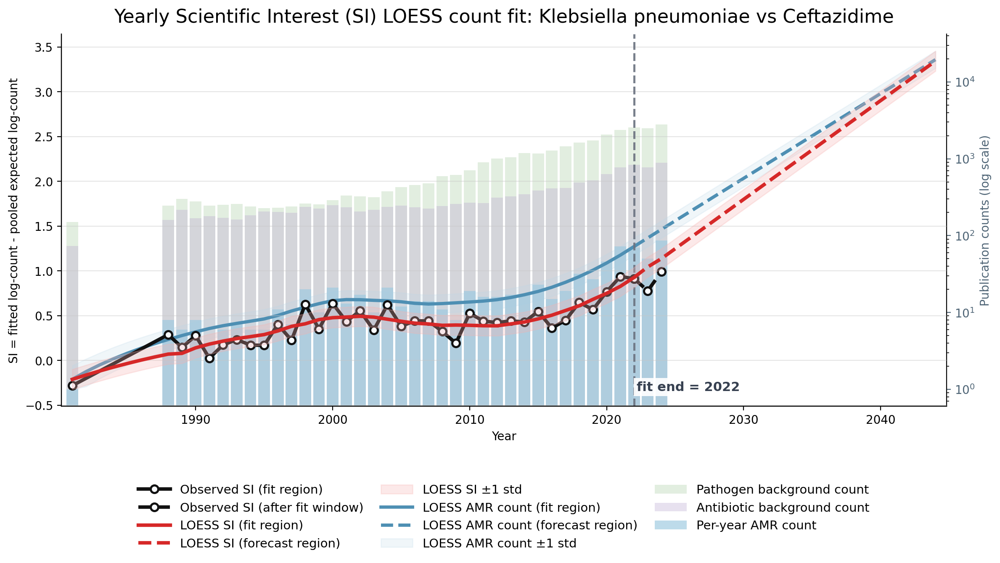

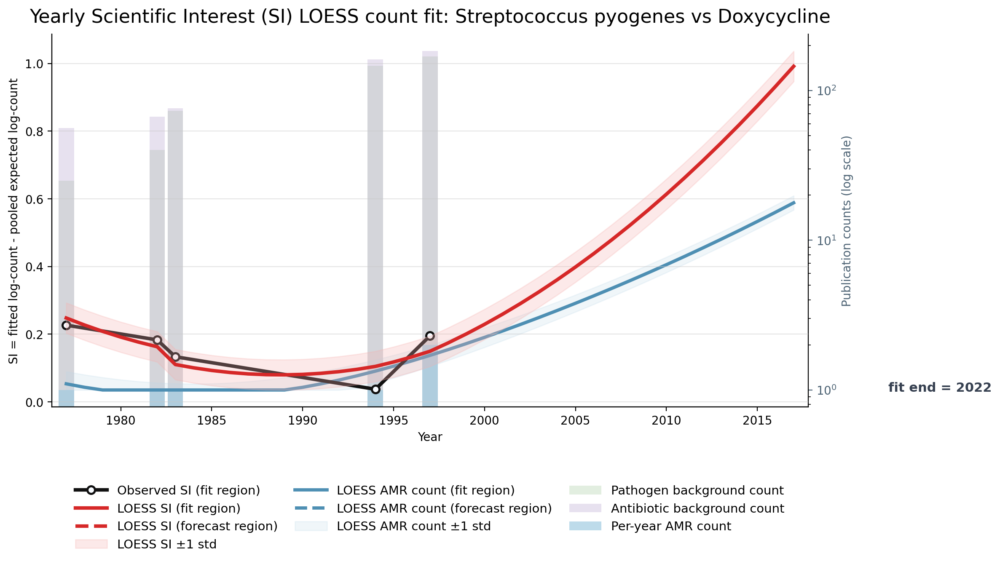

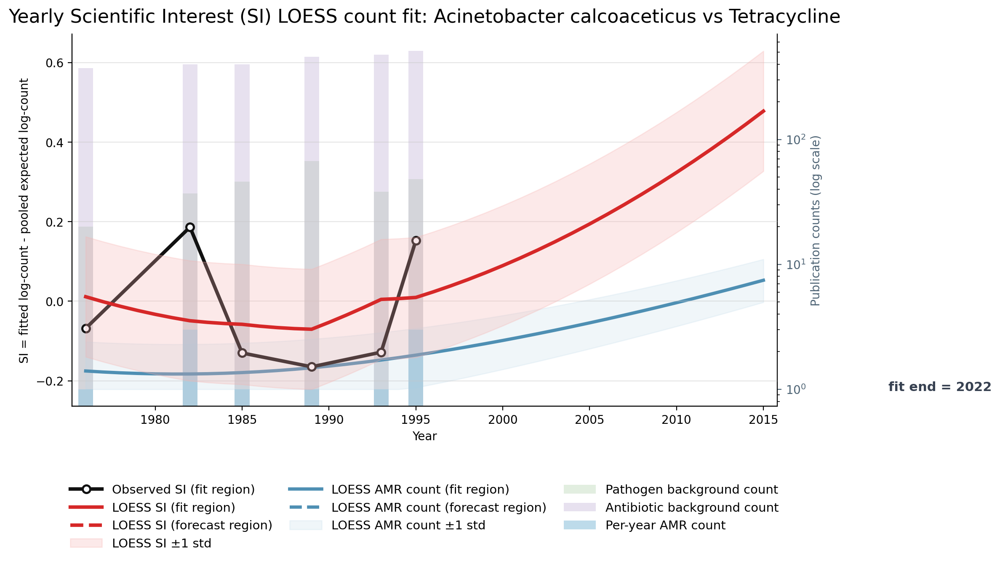

In [13]:
OUT_DIR = LEGACY_ASSETS_DIR / "interesting_yearly_si_pngs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

for pathogen, antibiotic in minimal_df[["pathogen", "antibiotic"]].values:
    result = plot_yearly_si_pair(
        si_df=si_df,
        pathogen=pathogen,
        antibiotic=antibiotic,
        fit_start_year=1970,
        fit_end_year=2022,
        num_additional_years=20,
        loess_frac=0.6,
        loess_degree=2,
        tail_damping_years=None,
    )
    
    pathogen_slug = str(pathogen).replace("/", "_").replace(" ", "_")
    antibiotic_slug = str(antibiotic).replace("/", "_").replace(" ", "_")
    out_path = OUT_DIR / f"{pathogen_slug}__{antibiotic_slug}.png"
    
    result["figure"].savefig(out_path, dpi=200, bbox_inches="tight")
